# Fase 1: algoritmos de búsqueda en grafos para el movimiento en videojuegos

En un juego de estrategia, cuando se le ordena a una unidad que vaya a un punto del mapa, el juego tiene que calcular por dónde caminar: esquivar muros, evitar el terreno lento y llegar gastando lo menos posible. Ese cálculo es un problema de **búsqueda de rutas en un grafo**.

**Pregunta de investigación.** ¿Qué algoritmo de búsqueda en grafos ofrece el mejor equilibrio entre calidad de la ruta y costo de cómputo para mover una unidad en un mapa de cuadrícula con terreno de costo variable, muros y puntos de paso obligatorio?

**Hipótesis**

1. A* encuentra rutas del mismo costo que Dijkstra explorando menos vértices.
2. BFS solo es óptimo cuando todo el terreno cuesta lo mismo.
3. DFS y la búsqueda voraz exploran poco, pero no garantizan la mejor ruta.

In [1]:
import heapq
import math
import statistics
import time
from collections import deque
from itertools import combinations, permutations

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import to_rgb, to_rgba

## 1. El mapa como grafo

El mapa se escribe como texto, un carácter por casilla, así que editarlo es cambiar letras:

| Símbolo | Significado | Costo de entrar |
|---|---|---|
| `.` | Llano | 1 |
| `b` | Bosque | 3 |
| `a` | Agua | 5 |
| `#` | Muro | no se puede cruzar |
| `I` | Inicio | 1 |
| `M` | Meta | 1 |
| `*` | Item (punto de paso) | 1 |

El grafo $G = (V, E)$ que representa al mapa es:

- **Vértices**: las casillas transitables. Un muro no es un vértice.
- **Aristas**: cada par de casillas vecinas (arriba, abajo, izquierda, derecha) transitables.
- **Peso**: moverse a una casilla cuesta lo que cuesta su terreno. Entrar al agua cuesta 5 aunque se venga del llano.

In [2]:
COSTOS = {".": 1, "b": 3, "a": 5}


def leer_mapa(texto):
    """Convierte el texto de un mapa en los datos que usan los algoritmos.

    texto: mapa escrito con un carácter por casilla y una fila por línea.
    Las filas pueden tener distinto largo; lo que falte a la derecha se
    considera muro.

    Devuelve cuatro valores:
    - cuadricula: lista de filas con el terreno de cada casilla.
    - inicio y meta: posiciones como pares (fila, columna).
    - items: lista de posiciones de los puntos de paso.

    Lanza ValueError si hay un símbolo desconocido o si no hay exactamente
    un inicio y una meta.
    """
    # Cada línea del texto es una fila del mapa.
    filas = [linea.strip() for linea in texto.strip().splitlines()]
    # Las filas pueden medir distinto: las cortas se completan con muro a la
    # derecha para que la cuadrícula quede rectangular.
    ancho = max((len(fila) for fila in filas), default=0)
    filas = [fila.ljust(ancho, "#") for fila in filas]
    puntos = {"I": [], "M": [], "*": []}
    cuadricula = []
    for f, fila in enumerate(filas):
        terreno = ""
        for c, simbolo in enumerate(fila):
            # El inicio, la meta y los items se guardan aparte y su casilla se trata como llano.
            if simbolo in puntos:
                puntos[simbolo].append((f, c))
                simbolo = "."
            elif simbolo != "#" and simbolo not in COSTOS:
                raise ValueError(f"Símbolo desconocido '{simbolo}' en la fila {f}, columna {c}.")
            terreno += simbolo
        cuadricula.append(terreno)
    if len(puntos["I"]) != 1 or len(puntos["M"]) != 1:
        raise ValueError("El mapa necesita exactamente una I y una M.")
    return cuadricula, puntos["I"][0], puntos["M"][0], puntos["*"]


def vecinos(cuadricula, casilla):
    """Genera las aristas que salen de una casilla.

    Revisa las cuatro casillas contiguas (arriba, derecha, abajo, izquierda)
    y descarta las que quedan fuera del mapa o son muro.

    Produce pares (vecino, peso), donde el peso es el costo del terreno de
    la casilla vecina.
    """
    f, c = casilla
    # Las cuatro casillas contiguas: arriba, derecha, abajo e izquierda.
    for nf, nc in ((f - 1, c), (f, c + 1), (f + 1, c), (f, c - 1)):
        dentro = 0 <= nf < len(cuadricula) and 0 <= nc < len(cuadricula[0])
        # Solo hay arista si la vecina está dentro del mapa y no es muro.
        if dentro and cuadricula[nf][nc] != "#":
            yield (nf, nc), COSTOS[cuadricula[nf][nc]]


def costo_de(cuadricula, ruta):
    """Costo total de una ruta.

    ruta: lista de casillas consecutivas, o None si no hay ruta.

    Suma el costo de entrar a cada casilla después de la primera. Si la
    ruta es None devuelve infinito.
    """
    if ruta is None:
        return math.inf
    # La primera casilla no se cuenta porque la unidad ya está parada en ella.
    return sum(COSTOS[cuadricula[f][c]] for f, c in ruta[1:])

In [3]:
COLORES = {".": "#efe9d0", "b": "#6aa56a", "a": "#6fa8dc", "#": "#2b2b2b"}


def dibujar(cuadricula, inicio, meta, items=(), explorados=(), ruta=None, ax=None, titulo=""):
    """Dibuja el mapa y, si se indican, la exploración y la ruta de una búsqueda.

    explorados: casillas que revisó el algoritmo; se pintan de morado.
    ruta: lista de casillas; se dibuja como una línea roja.
    ax: eje de matplotlib donde dibujar. Si es None se crea una figura nueva.

    El inicio es un círculo verde, la meta una estrella naranja y los items
    rombos amarillos. Cada casilla queda delimitada por una cuadrícula.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(len(cuadricula[0]) * 0.35 + 1, len(cuadricula) * 0.35 + 1))
    # Cada casilla se pinta con el color de su terreno.
    ax.imshow([[to_rgb(COLORES[s]) for s in fila] for fila in cuadricula])
    # Capa transparente encima del mapa: solo se colorean las casillas exploradas.
    capa = [[(0, 0, 0, 0)] * len(cuadricula[0]) for _ in cuadricula]
    for f, c in explorados:
        capa[f][c] = to_rgba("#7b2cbf", 0.4)
    ax.imshow(capa)
    if ruta:
        # matplotlib espera (x, y), que aquí es (columna, fila).
        ax.plot([c for _, c in ruta], [f for f, _ in ruta], color="#d00000", linewidth=2.2)
    for f, c in items:
        ax.plot(c, f, "D", color="#ffc300", markeredgecolor="black", markersize=8)
    ax.plot(inicio[1], inicio[0], "o", color="#38b000", markeredgecolor="black", markersize=10)
    ax.plot(meta[1], meta[0], "*", color="#ff7b00", markeredgecolor="black", markersize=15)
    # Las líneas de la cuadrícula van en los bordes de las casillas, que
    # quedan a media unidad de cada centro.
    ax.set_xticks([c - 0.5 for c in range(1, len(cuadricula[0]))], minor=True)
    ax.set_yticks([f - 0.5 for f in range(1, len(cuadricula))], minor=True)
    ax.grid(which="minor", color="#8a8a8a", linewidth=0.5)
    ax.tick_params(which="both", length=0)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(titulo, fontsize=10)

### El mismo mapa dibujado como grafo

La cuadrícula coloreada y el grafo son dos formas de ver lo mismo. Con NetworkX se puede construir el grafo de forma explícita: cada casilla transitable es un nodo y cada par de casillas vecinas una arista. El número dentro de cada nodo es lo que cuesta entrar a esa casilla. El muro no aparece porque no es un vértice.

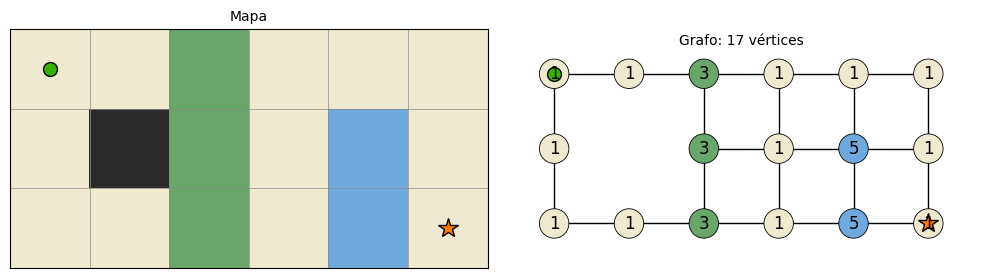

In [4]:
def a_grafo(cuadricula):
    """Construye el grafo dirigido de NetworkX equivalente a la cuadrícula.

    Cada casilla transitable es un nodo. Hay una arista de u a v por cada par
    de casillas vecinas, con el atributo weight igual al costo de entrar a v.
    Es dirigido porque ir del llano al agua cuesta 5 y volver cuesta 1.
    """
    grafo = nx.DiGraph()
    for f, fila in enumerate(cuadricula):
        for c, simbolo in enumerate(fila):
            # Un muro no genera nodo ni aristas.
            if simbolo != "#":
                grafo.add_node((f, c))
                for vecino, peso in vecinos(cuadricula, (f, c)):
                    # Arista dirigida cuyo peso es el costo de entrar a la casilla vecina.
                    grafo.add_edge((f, c), vecino, weight=peso)
    return grafo


def dibujar_grafo(cuadricula, inicio, meta, items=(), ax=None, titulo=""):
    """Dibuja el mapa como grafo: un nodo por casilla transitable y sus aristas.

    Cada nodo se coloca en la posición de su casilla y se pinta del color de
    su terreno. Si el mapa es pequeño, dentro del nodo se escribe lo que
    cuesta entrar a esa casilla. Los muros no aparecen porque no son vértices.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(len(cuadricula[0]) * 0.35 + 1, len(cuadricula) * 0.35 + 1))
    grafo = a_grafo(cuadricula)
    # La fila se niega para que la fila 0 quede arriba, igual que en el mapa.
    posiciones = {(f, c): (c, -f) for f, c in grafo.nodes}
    # Los nodos se encogen en mapas anchos para que no se encimen.
    tamano = min(450, 60000 / len(cuadricula[0]) ** 2)
    # Se dibuja sin dirección para que cada par de vecinos tenga una sola línea.
    nx.draw(
        grafo.to_undirected(), pos=posiciones, ax=ax,
        node_color=[COLORES[cuadricula[f][c]] for f, c in grafo.nodes],
        node_size=tamano, edgecolors="black", linewidths=0.6, width=1,
    )
    # Los costos solo se escriben si el nodo es lo bastante grande para leerlos.
    if tamano >= 300:
        etiquetas = {(f, c): COSTOS[cuadricula[f][c]] for f, c in grafo.nodes}
        nx.draw_networkx_labels(grafo, posiciones, labels=etiquetas, ax=ax)
    for f, c in items:
        ax.plot(c, -f, "D", color="#ffc300", markeredgecolor="black", markersize=8)
    ax.plot(inicio[1], -inicio[0], "o", color="#38b000", markeredgecolor="black", markersize=10)
    ax.plot(meta[1], -meta[0], "*", color="#ff7b00", markeredgecolor="black", markersize=15)
    ax.set_aspect("equal")
    # Margen para que los nodos de la orilla no queden recortados.
    ax.margins(0.08)
    ax.set_title(titulo, fontsize=10)


def dibujar_mapa_y_grafo(cuadricula, inicio, meta, items=(), titulo=""):
    """Muestra el mapa cuadriculado y su grafo, uno al lado del otro."""
    # Los mínimos evitan que un mapa de pocas casillas salga diminuto.
    ancho = max(10, len(cuadricula[0]) * 0.55 + 2)
    alto = max(3, len(cuadricula) * 0.27 + 1.2)
    figura, (izq, der) = plt.subplots(1, 2, figsize=(ancho, alto))
    dibujar(cuadricula, inicio, meta, items=items, ax=izq, titulo="Mapa")
    vertices = sum(simbolo != "#" for fila in cuadricula for simbolo in fila)
    dibujar_grafo(cuadricula, inicio, meta, items=items, ax=der, titulo=f"Grafo: {vertices} vértices")
    if titulo:
        figura.suptitle(titulo)
    figura.tight_layout()
    plt.show()


MINI = '''
I.b...
.#b.a.
..b.aM
'''

cuadricula, inicio, meta, items = leer_mapa(MINI)
dibujar_mapa_y_grafo(cuadricula, inicio, meta)

Un mapa más grande, que se usa después en la comparación. Aquí los nodos ya no llevan número para que quepan, pero el color sigue indicando el terreno.

Casillas: 12 x 24 = 288
Vértices: 267
Aristas:  474
Suma de grados: 948, el doble de las aristas (lema del apretón de manos)


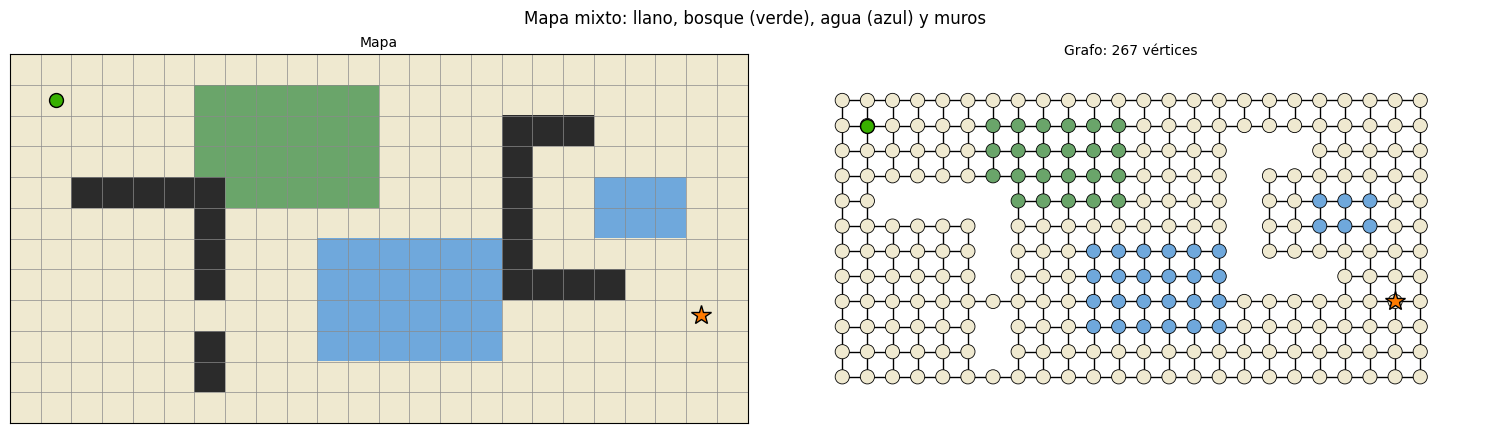

In [5]:
MIXTO = '''
........................
.I....bbbbbb............
......bbbbbb....###.....
......bbbbbb....#.......
..#####bbbbb....#..aaa..
......#.........#..aaa..
......#...aaaaaa#.......
......#...aaaaaa####....
..........aaaaaa......M.
......#...aaaaaa........
......#.................
........................
'''

cuadricula, inicio, meta, items = leer_mapa(MIXTO)
vertices = [(f, c) for f, fila in enumerate(cuadricula) for c, s in enumerate(fila) if s != "#"]
grados = [len(list(vecinos(cuadricula, v))) for v in vertices]

print(f"Casillas: {len(cuadricula)} x {len(cuadricula[0])} = {len(cuadricula) * len(cuadricula[0])}")
print(f"Vértices: {len(vertices)}")
print(f"Aristas:  {sum(grados) // 2}")
print(f"Suma de grados: {sum(grados)}, el doble de las aristas (lema del apretón de manos)")
dibujar_mapa_y_grafo(cuadricula, inicio, meta, titulo="Mapa mixto: llano, bosque (verde), agua (azul) y muros")

## 2. Los algoritmos

Los cinco siguen el mismo esquema: mantienen una **frontera** de vértices descubiertos pero aún no explorados, sacan uno, revisan sus vecinos y repiten hasta sacar la meta. Lo único que cambia es **cuál sacan primero**.

| Algoritmo | Qué vértice saca de la frontera | Estructura | Garantiza el menor costo |
|---|---|---|---|
| BFS | El que lleva más tiempo esperando | Cola | Solo si todos los pesos son iguales |
| DFS | El descubierto más recientemente | Pila | No |
| Dijkstra | El de menor costo acumulado $g(v)$ | Cola de prioridad | Sí |
| Voraz | El que parece más cerca de la meta, $h(v)$ | Cola de prioridad | No |
| A* | El de menor $g(v) + h(v)$ | Cola de prioridad | Sí, si $h$ nunca sobrestima |

Todas las funciones reciben `(cuadricula, inicio, meta)` y devuelven la ruta (o `None` si no existe) y la lista de vértices explorados en orden.

In [6]:
def reconstruir(padres, meta):
    """Arma la ruta desde el inicio hasta la meta.

    padres: diccionario que guarda, para cada vértice descubierto, el
    vértice desde el que se llegó a él. El inicio tiene padre None.

    Se recorre hacia atrás desde la meta y al final se invierte la lista.
    """
    ruta = []
    while meta is not None:
        ruta.append(meta)
        # Se retrocede al vértice desde el que se llegó.
        meta = padres[meta]
    # La lista quedó de la meta al inicio, así que se invierte.
    return ruta[::-1]


def bfs(cuadricula, inicio, meta):
    """Búsqueda en anchura (BFS).

    La frontera es una cola: sale primero el vértice que entró primero, así
    que el mapa se explora por capas de distancia creciente al inicio.

    Devuelve (ruta, explorados). La ruta es la de menos pasos, o None si la
    meta no es alcanzable.
    """
    # Cola con los vértices descubiertos que faltan por explorar.
    frontera = deque([inicio])
    # Guarda desde qué vértice se llegó a cada uno. También indica cuáles ya se descubrieron.
    padres = {inicio: None}
    explorados = []
    while frontera:
        # Sale el vértice que lleva más tiempo esperando en la cola.
        actual = frontera.popleft()
        explorados.append(actual)
        # Al sacar la meta la búsqueda termina.
        if actual == meta:
            return reconstruir(padres, meta), explorados
        for vecino, _ in vecinos(cuadricula, actual):
            # Cada vértice entra a la cola una sola vez: la primera vez que se descubre.
            if vecino not in padres:
                padres[vecino] = actual
                frontera.append(vecino)
    return None, explorados

In [7]:
def dfs(cuadricula, inicio, meta):
    """Búsqueda en profundidad (DFS).

    La frontera es una pila: sale primero el vértice que entró al último,
    así que avanza por un camino hasta que no puede seguir y entonces
    retrocede.

    Devuelve (ruta, explorados). La ruta es la primera que encuentra, sin
    garantía de que sea corta, o None si la meta no es alcanzable.
    """
    # Pila: una lista donde se mete y se saca por el final.
    frontera = [inicio]
    padres = {inicio: None}
    explorados = []
    while frontera:
        # Sale el vértice que entró al último.
        actual = frontera.pop()
        # Un vértice puede estar varias veces en la pila; solo se explora la primera vez que sale.
        if actual in explorados:
            continue
        explorados.append(actual)
        if actual == meta:
            return reconstruir(padres, meta), explorados
        for vecino, _ in vecinos(cuadricula, actual):
            if vecino not in explorados:
                # Se apila el vecino para seguir avanzando por él antes que por los demás.
                padres[vecino] = actual
                frontera.append(vecino)
    return None, explorados

In [8]:
def dijkstra(cuadricula, inicio, meta):
    """Algoritmo de Dijkstra.

    La frontera es una cola de prioridad ordenada por el costo acumulado
    desde el inicio: siempre sale el vértice más barato de alcanzar.

    Devuelve (ruta, explorados). La ruta es la de menor costo, o None si la
    meta no es alcanzable.
    """
    # Cola de prioridad con pares (costo acumulado, vértice).
    frontera = [(0, inicio)]
    # Menor costo conocido para llegar a cada vértice.
    costos = {inicio: 0}
    padres = {inicio: None}
    explorados = []
    while frontera:
        # Sale el vértice con el menor costo acumulado.
        costo, actual = heapq.heappop(frontera)
        if costo > costos[actual]:
            # Entrada vieja: ya se encontró un camino más barato a este vértice.
            continue
        explorados.append(actual)
        if actual == meta:
            return reconstruir(padres, meta), explorados
        for vecino, peso in vecinos(cuadricula, actual):
            # Costo de llegar al vecino pasando por el vértice actual.
            nuevo = costo + peso
            # Relajación: si este camino es más barato que el conocido, lo reemplaza.
            if nuevo < costos.get(vecino, math.inf):
                costos[vecino] = nuevo
                padres[vecino] = actual
                heapq.heappush(frontera, (nuevo, vecino))
    return None, explorados

La **heurística** $h(v)$ estima cuánto falta para llegar a la meta. Aquí es la distancia Manhattan: filas más columnas de diferencia. Nunca sobrestima el costo real, porque ninguna ruta puede tener menos pasos que esa distancia y ningún paso cuesta menos de 1. Esa propiedad se llama **admisibilidad** y es la que le permite a A* garantizar la ruta óptima.

In [9]:
def heuristica(a, b):
    """Distancia Manhattan entre dos casillas.

    Es el número mínimo de pasos entre a y b si no hubiera muros. Como cada
    paso cuesta al menos 1, nunca sobrestima el costo real.
    """
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def voraz(cuadricula, inicio, meta):
    """Búsqueda voraz (Greedy Best-First).

    La frontera es una cola de prioridad ordenada solo por la heurística:
    siempre sale el vértice que parece más cercano a la meta, sin importar
    cuánto costó llegar a él.

    Devuelve (ruta, explorados). La ruta no es necesariamente la de menor
    costo. Es None si la meta no es alcanzable.
    """
    # Cola de prioridad con pares (distancia estimada a la meta, vértice).
    frontera = [(heuristica(inicio, meta), inicio)]
    padres = {inicio: None}
    explorados = []
    while frontera:
        # Sale el vértice que parece más cercano a la meta.
        _, actual = heapq.heappop(frontera)
        explorados.append(actual)
        if actual == meta:
            return reconstruir(padres, meta), explorados
        for vecino, _ in vecinos(cuadricula, actual):
            if vecino not in padres:
                padres[vecino] = actual
                # La prioridad solo mira lo que falta, no lo que ya costó llegar.
                heapq.heappush(frontera, (heuristica(vecino, meta), vecino))
    return None, explorados

In [10]:
def a_estrella(cuadricula, inicio, meta):
    """Algoritmo A*.

    Funciona como Dijkstra, pero la prioridad de cada vértice es el costo
    acumulado desde el inicio más el costo estimado hasta la meta. Así la
    exploración se dirige hacia la meta sin perder la garantía de optimalidad.

    Devuelve (ruta, explorados). La ruta es la de menor costo, o None si la
    meta no es alcanzable.
    """
    # El segundo valor de la prioridad desempata a favor del vértice más cercano a la meta.
    h = heuristica(inicio, meta)
    # Cola de prioridad con ternas (costo acumulado + estimado, estimado, vértice).
    frontera = [(h, h, inicio)]
    costos = {inicio: 0}
    padres = {inicio: None}
    explorados = []
    # Vértices ya explorados, para no repetirlos.
    cerrados = set()
    while frontera:
        _, _, actual = heapq.heappop(frontera)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        explorados.append(actual)
        if actual == meta:
            return reconstruir(padres, meta), explorados
        for vecino, peso in vecinos(cuadricula, actual):
            # Costo real de llegar al vecino pasando por el vértice actual.
            nuevo = costos[actual] + peso
            # Misma relajación que en Dijkstra.
            if nuevo < costos.get(vecino, math.inf):
                costos[vecino] = nuevo
                padres[vecino] = actual
                h = heuristica(vecino, meta)
                # Prioridad: lo que ya costó llegar más lo que se estima que falta.
                heapq.heappush(frontera, (nuevo + h, h, vecino))
    return None, explorados


ALGORITMOS = {"BFS": bfs, "DFS": dfs, "Dijkstra": dijkstra, "Voraz": voraz, "A*": a_estrella}

## 3. Comparación

Para cada mapa se mide:

- **Costo** de la ruta. Es óptima si iguala al costo de Dijkstra.
- **Explorados**: cuántos vértices revisó el algoritmo. Mide el trabajo sin depender de la computadora.
- **Tiempo**: mediana de 20 corridas, en milisegundos. Cambia de una máquina a otra.

Para cada mapa se muestra primero la cuadrícula junto a su grafo y después lo que hizo cada algoritmo. En las figuras, el círculo verde es el inicio, la estrella naranja es la meta, las casillas moradas son los vértices explorados y la línea roja es la ruta.

In [11]:
def comparar(texto, titulo):
    """Ejecuta los cinco algoritmos sobre un mapa y muestra los resultados.

    texto: mapa escrito como texto.
    titulo: título de la figura.

    Dibuja el mapa junto a su grafo, imprime una tabla con costo,
    optimalidad, vértices explorados y tiempo de cada algoritmo, y dibuja la
    exploración y la ruta de cada uno. El tiempo es la mediana de 20 corridas.
    """
    cuadricula, inicio, meta, items = leer_mapa(texto)
    # El costo de Dijkstra es la referencia para decidir si una ruta es óptima.
    optimo = costo_de(cuadricula, dijkstra(cuadricula, inicio, meta)[0])
    dibujar_mapa_y_grafo(cuadricula, inicio, meta, titulo=titulo)
    figura, ejes = plt.subplots(2, 3, figsize=(len(cuadricula[0]) * 0.55 + 2, len(cuadricula) * 0.5 + 2))
    ejes = ejes.flatten()
    # La figura tiene seis espacios y solo hay cinco algoritmos: el último se oculta.
    ejes[5].axis("off")
    print(f"{'Algoritmo':<10}{'Costo':>7}{'Óptima':>8}{'Explorados':>12}{'Tiempo ms':>11}")
    for ax, (nombre, algoritmo) in zip(ejes, ALGORITMOS.items()):
        tiempos = []
        # Se mide 20 veces y se toma la mediana para reducir el ruido de la medición.
        for _ in range(20):
            comienzo = time.perf_counter()
            ruta, explorados = algoritmo(cuadricula, inicio, meta)
            tiempos.append((time.perf_counter() - comienzo) * 1000)
        costo = costo_de(cuadricula, ruta)
        if ruta is None:
            costo_texto, optima = "-", "-"
        else:
            costo_texto, optima = str(costo), "sí" if costo == optimo else "no"
        print(f"{nombre:<10}{costo_texto:>7}{optima:>8}{len(explorados):>12}{statistics.median(tiempos):>11.3f}")
        dibujar(cuadricula, inicio, meta, explorados=explorados, ruta=ruta, ax=ax,
                titulo=f"{nombre}: costo {costo_texto}, explorados {len(explorados)}")
    figura.tight_layout()
    plt.show()

### 3.1 Mapa abierto con costo uniforme

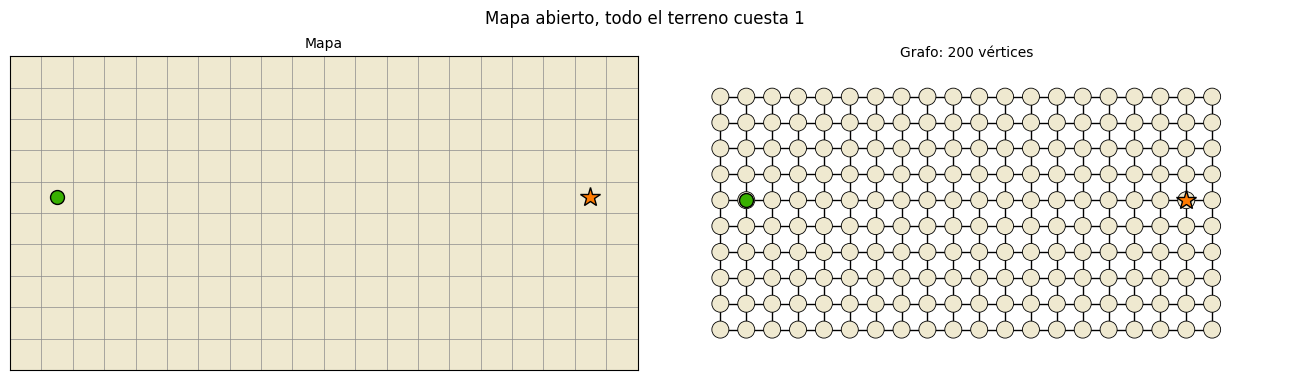

Algoritmo   Costo  Óptima  Explorados  Tiempo ms
BFS            17      sí         160      0.267
DFS           103      no         104      0.511
Dijkstra       17      sí         160      0.343
Voraz          17      sí          18      0.059
A*             17      sí          18      0.064


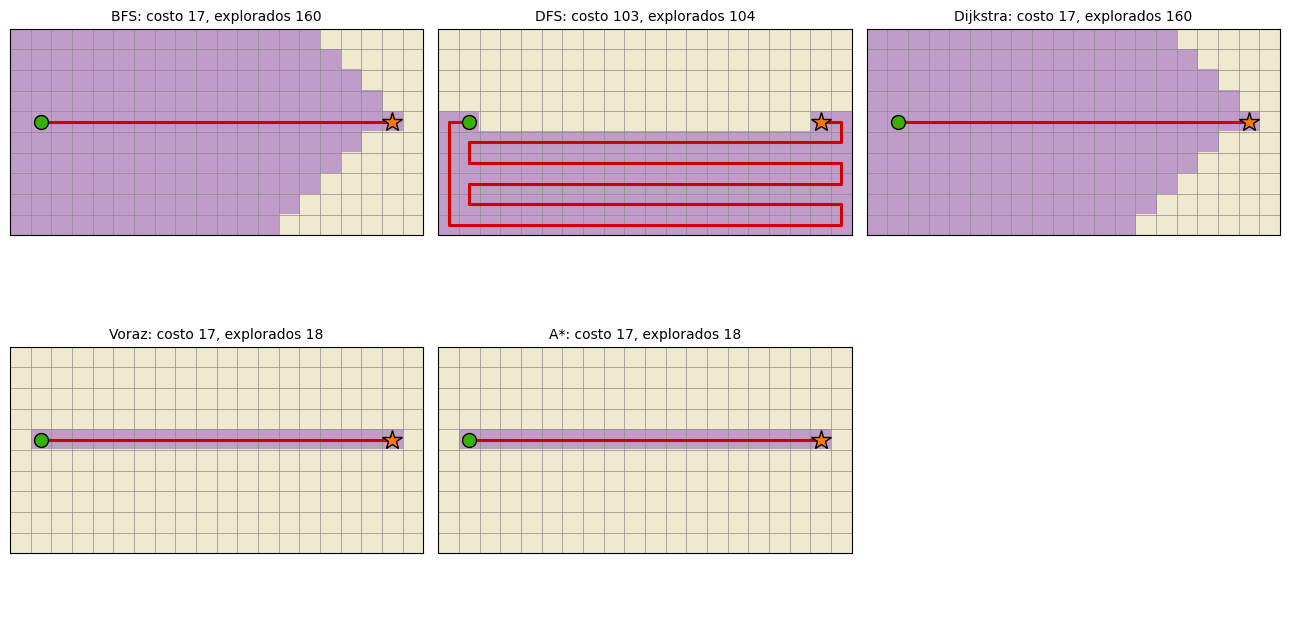

In [12]:
ABIERTO = '''
....................
....................
....................
....................
.I................M.
....................
....................
....................
....................
....................
'''
comparar(ABIERTO, "Mapa abierto, todo el terreno cuesta 1")

- Con todos los pesos iguales, BFS y Dijkstra hacen lo mismo: exploran en círculos crecientes alrededor del inicio y encuentran la ruta óptima después de revisar 160 de las 200 casillas.
- A* y la búsqueda voraz van directo a la meta y exploran solo las 18 casillas de la ruta.
- DFS encuentra una ruta, pero recorre el mapa en zigzag: costo 103 contra el óptimo de 17.

### 3.2 Terreno mixto

El caso parecido a un juego de estrategia: hay bosque, agua y muros, y el camino con menos pasos no es el más barato.

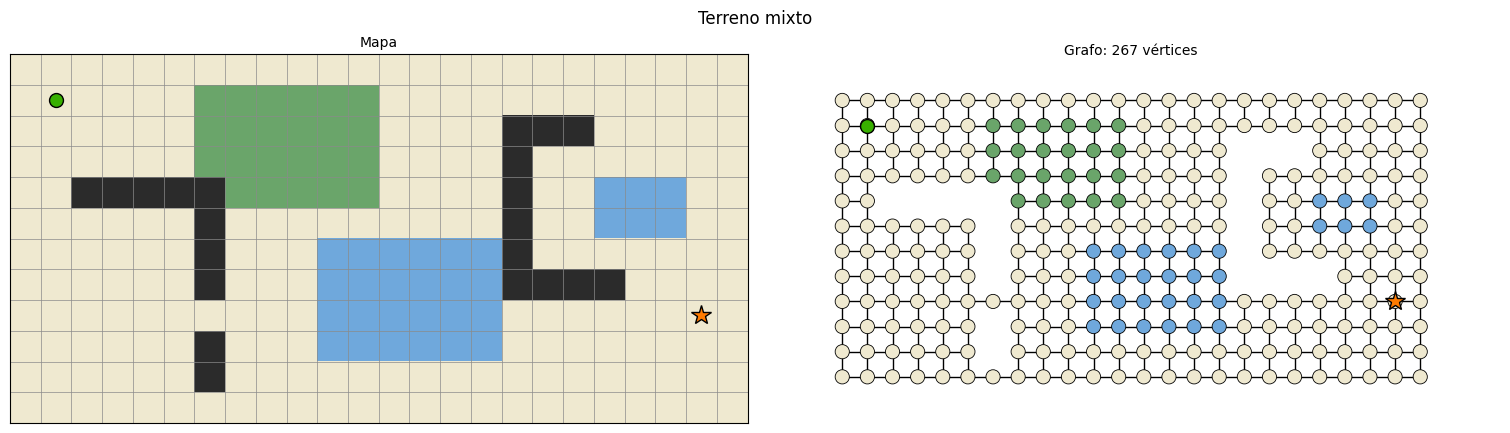

Algoritmo   Costo  Óptima  Explorados  Tiempo ms
BFS            40      no         254      0.379
DFS            94      no          71      0.285
Dijkstra       30      sí         252      0.570
Voraz          40      no          29      0.085
A*             30      sí          83      0.265


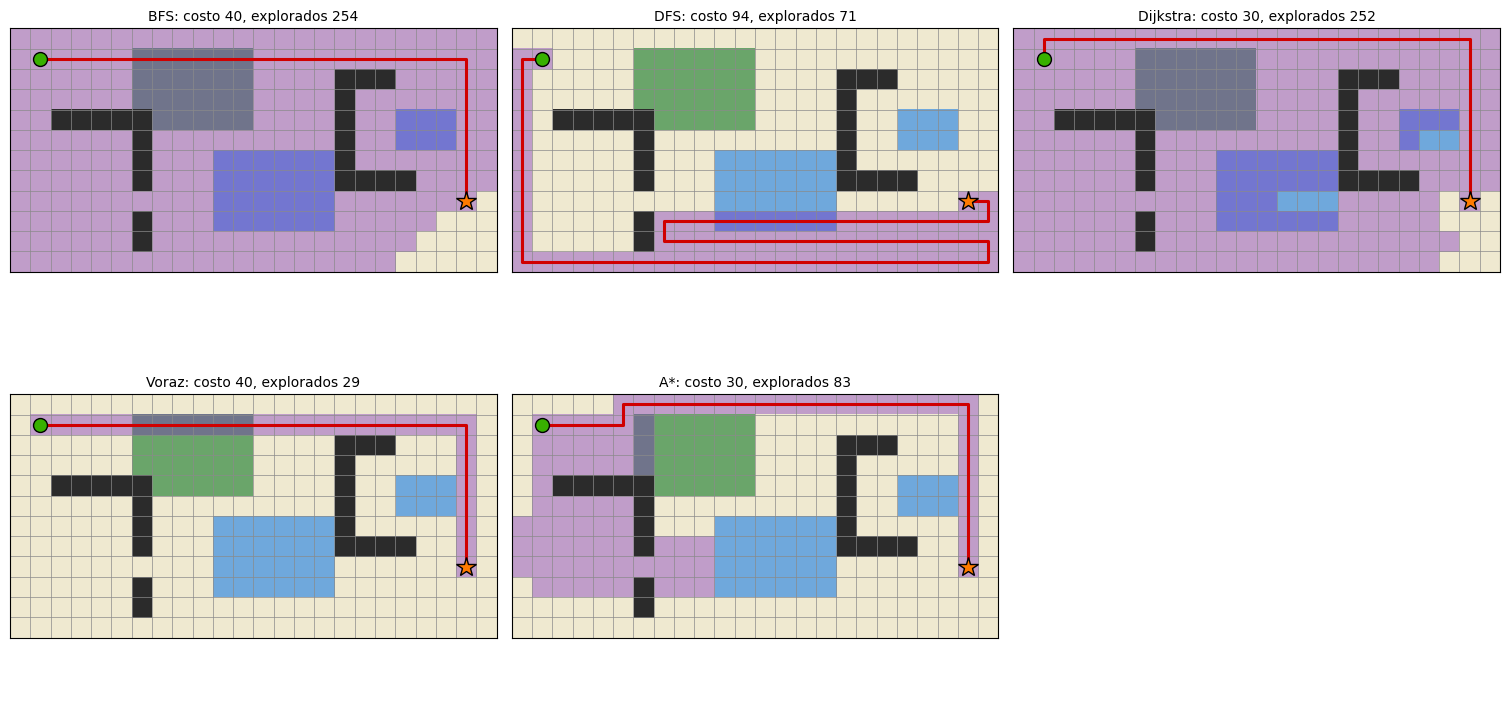

In [13]:
comparar(MIXTO, "Terreno mixto")

- BFS deja de ser óptimo: cuenta pasos y no pesos, así que cruza el agua y su ruta cuesta 40 en lugar de 30.
- Dijkstra y A* devuelven el mismo costo óptimo, pero A* explora 83 vértices y Dijkstra 252, la tercera parte.
- La búsqueda voraz explora apenas 29 vértices y paga 40: llega rápido a una ruta cara.
- DFS devuelve una ruta de costo 94, más del triple del óptimo.

### 3.3 Laberinto

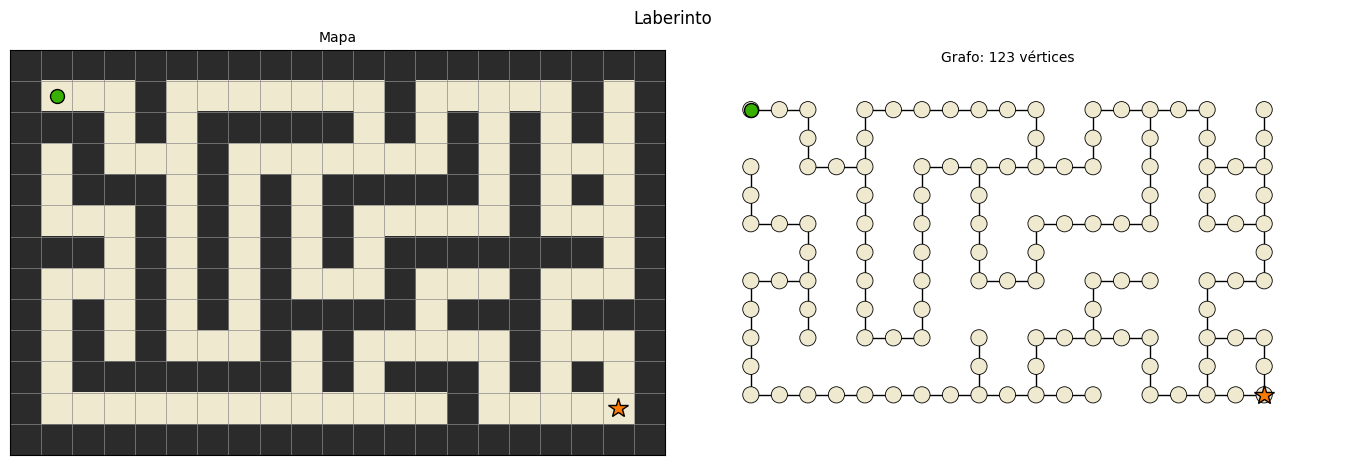

Algoritmo   Costo  Óptima  Explorados  Tiempo ms
BFS            40      sí          82      0.111
DFS            56      no         115      0.438
Dijkstra       40      sí          83      0.144
Voraz          48      no          49      0.109
A*             40      sí          73      0.152


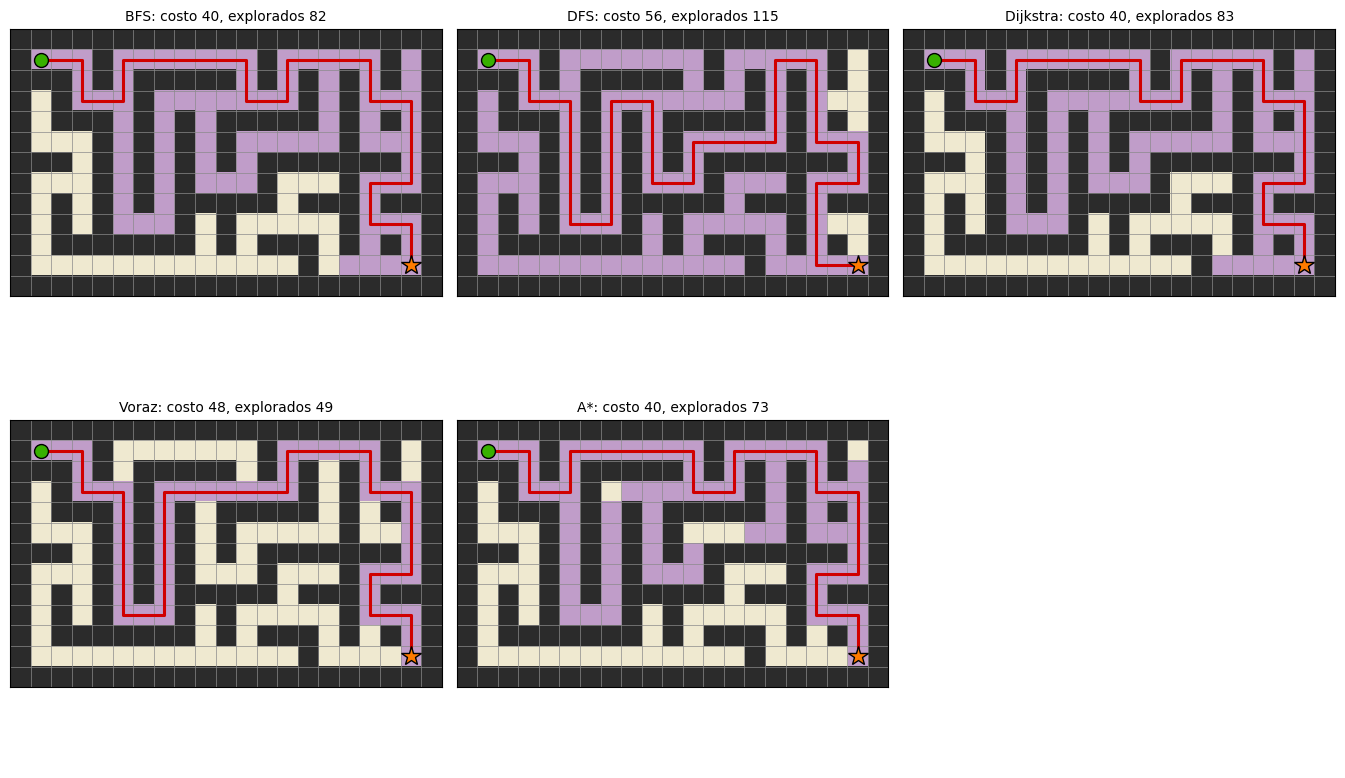

In [14]:
LABERINTO = '''
#####################
#I..#.......#.....#.#
###.#.#####.#.#.#.#.#
#.#...#.......#.#...#
#.###.#.#.#####.#.#.#
#...#.#.#.#.....#...#
###.#.#.#.#.#######.#
#...#.#.#...#...#...#
#.#.#.#.#####.###.###
#.#.#...#.#.....#...#
#.#######.#.###.#.#.#
#.............#....M#
#####################
'''
comparar(LABERINTO, "Laberinto")

- En un laberinto la ventaja de A* casi desaparece: explora 73 vértices contra 83 de Dijkstra. La distancia en línea recta dice poco cuando los pasillos obligan a alejarse de la meta para poder llegar.
- BFS vuelve a ser óptimo porque todos los pasillos cuestan 1.
- La búsqueda voraz y DFS encuentran la salida por caminos más largos (48 y 56 contra 40).

### 3.4 Mapa sin solución

La meta está encerrada entre muros.

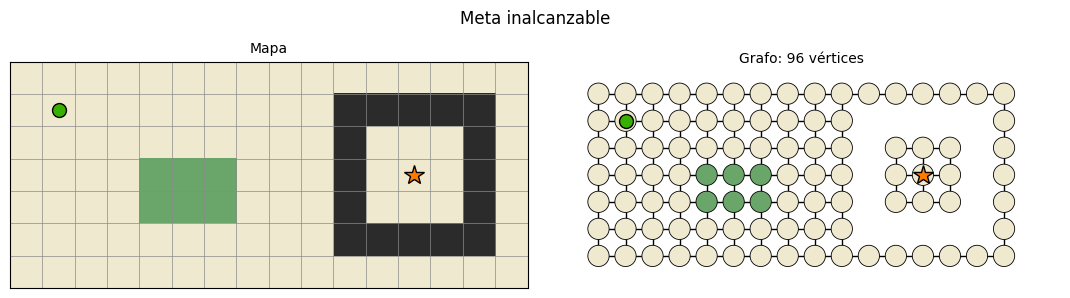

Algoritmo   Costo  Óptima  Explorados  Tiempo ms
BFS             -       -          87      0.160
DFS             -       -          87      0.409
Dijkstra        -       -          87      0.205
Voraz           -       -          87      0.164
A*              -       -          87      0.208


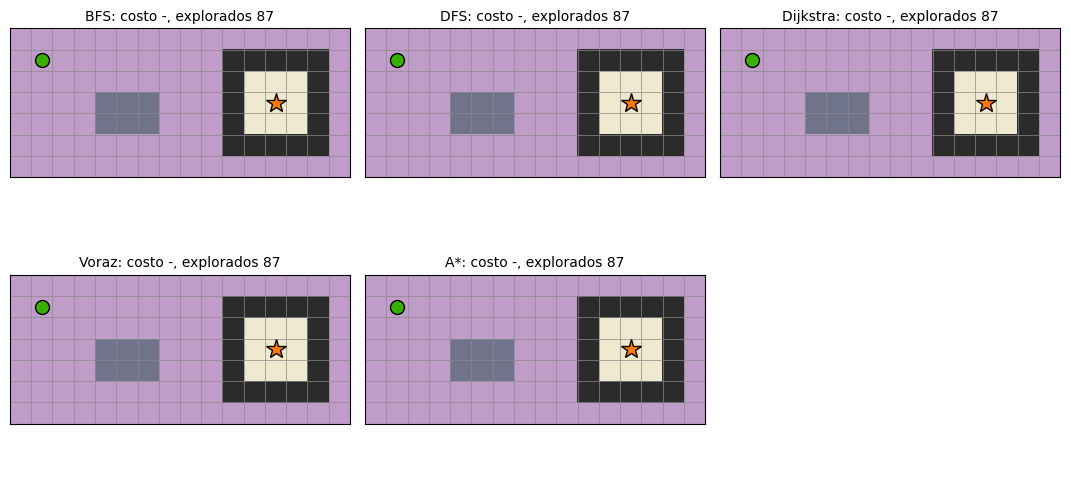

In [15]:
SIN_SOLUCION = '''
................
.I........#####.
..........#...#.
....bbb...#.M.#.
....bbb...#...#.
..........#####.
................
'''
comparar(SIN_SOLUCION, "Meta inalcanzable")

- Los cinco algoritmos terminan y reportan que no hay ruta, y los cinco exploran exactamente los mismos 87 vértices: toda la **componente conexa** del inicio.
- Cuando no hay ruta ninguna heurística ayuda. Es el peor caso para todos.

### 3.5 Validación con NetworkX

NetworkX trae sus propias implementaciones de Dijkstra y de A*. Si las de este notebook están bien hechas, el costo de la ruta óptima tiene que coincidir con el de NetworkX en todos los mapas.

In [16]:
print(f"{'Mapa':<14}{'Dijkstra':>10}{'A*':>6}{'NetworkX Dijkstra':>20}{'NetworkX A*':>14}{'Coinciden':>11}")
for nombre, texto in [("Abierto", ABIERTO), ("Mixto", MIXTO), ("Laberinto", LABERINTO), ("Sin solución", SIN_SOLUCION)]:
    cuadricula, inicio, meta, items = leer_mapa(texto)
    grafo = a_grafo(cuadricula)
    propio_dijkstra = costo_de(cuadricula, dijkstra(cuadricula, inicio, meta)[0])
    propio_a_estrella = costo_de(cuadricula, a_estrella(cuadricula, inicio, meta)[0])
    try:
        nx_dijkstra = nx.dijkstra_path_length(grafo, inicio, meta, weight="weight")
        nx_a_estrella = nx.astar_path_length(grafo, inicio, meta, heuristic=heuristica, weight="weight")
    except nx.NetworkXNoPath:
        # NetworkX avisa con una excepción cuando no existe ruta.
        nx_dijkstra = nx_a_estrella = math.inf
    coinciden = propio_dijkstra == propio_a_estrella == nx_dijkstra == nx_a_estrella
    print(f"{nombre:<14}{propio_dijkstra:>10}{propio_a_estrella:>6}{nx_dijkstra:>20}{nx_a_estrella:>14}{'sí' if coinciden else 'no':>11}")

Mapa            Dijkstra    A*   NetworkX Dijkstra   NetworkX A*  Coinciden
Abierto               17    17                  17            17         sí
Mixto                 30    30                  30            30         sí
Laberinto             40    40                  40            40         sí
Sin solución         inf   inf                 inf           inf         sí


Los costos coinciden en los cuatro mapas, incluido el caso sin solución, donde `inf` significa que no existe ruta. NetworkX solo se usa aquí y para dibujar el grafo: sus funciones devuelven la ruta pero no cuántos vértices exploraron, que es justo lo que se quiere comparar.

## 4. Items: pasar por varios puntos antes de la meta

Ahora la unidad debe recoger todos los items y después llegar a la meta. El problema se resuelve en dos niveles:

1. Se calcula con Dijkstra la ruta más corta entre cada par de puntos de interés (inicio, items y meta). El resultado es un **grafo completo** pequeño, donde cada arista pesa lo que cuesta ir de un punto a otro.
2. Sobre ese grafo se decide el **orden de visita**. Con $n$ items hay $n!$ órdenes posibles.

Se comparan dos estrategias:

- **Fuerza bruta**: evalúa las $n!$ permutaciones y se queda con la mejor. Siempre es óptima.
- **Vecino más cercano**: va siempre al item pendiente más cercano. Construye un solo orden.

In [17]:
def tramos_entre(cuadricula, puntos):
    """Calcula con Dijkstra la ruta más corta entre cada par de puntos.

    puntos: lista de casillas de interés (inicio, items y meta).

    Devuelve un diccionario cuya clave es el par (origen, destino) y cuyo
    valor es la ruta entre ambos, o None si no existe.
    """
    return {(a, b): dijkstra(cuadricula, a, b)[0] for a in puntos for b in puntos if a != b}


def costo_del_orden(cuadricula, tramos, orden):
    """Costo de visitar los puntos en el orden dado.

    orden: lista de puntos que empieza en el inicio y termina en la meta.

    Suma el costo del tramo entre cada punto y el siguiente.
    """
    return sum(costo_de(cuadricula, tramos[(a, b)]) for a, b in zip(orden, orden[1:]))


def fuerza_bruta(cuadricula, tramos, inicio, items, meta):
    """Elige el orden de visita probando todas las permutaciones de los items.

    Devuelve (orden, evaluados): el orden de menor costo y cuántos órdenes
    se compararon, que son n! para n items.
    """
    # Todas las permutaciones de los items, siempre entre el inicio y la meta.
    ordenes = [[inicio, *p, meta] for p in permutations(items)]
    mejor = min(ordenes, key=lambda orden: costo_del_orden(cuadricula, tramos, orden))
    return mejor, len(ordenes)


def vecino_mas_cercano(cuadricula, tramos, inicio, items, meta):
    """Elige el orden de visita yendo siempre al item pendiente más cercano.

    Devuelve (orden, evaluados). Solo construye un orden, así que evaluados
    vale 1. El resultado no es necesariamente el de menor costo.
    """
    orden = [inicio]
    pendientes = list(items)
    while pendientes:
        # De los items pendientes, el más barato de alcanzar desde el punto actual.
        siguiente = min(pendientes, key=lambda item: costo_de(cuadricula, tramos[(orden[-1], item)]))
        pendientes.remove(siguiente)
        orden.append(siguiente)
    return orden + [meta], 1


def dibujar_grafo_completo(texto):
    """Muestra cómo un mapa con items se reduce a un grafo completo.

    A la izquierda dibuja el mapa con la ruta más corta entre cada par de
    puntos de interés (inicio, items y meta). A la derecha dibuja el grafo
    completo: un nodo por punto y una arista por cada par, cuyo peso es el
    costo de esa ruta. También imprime la tabla de costos.
    """
    cuadricula, inicio, meta, items = leer_mapa(texto)
    puntos = [inicio, *items, meta]
    # Nombres cortos para los nodos: I, los items numerados y M.
    nombres = ["I"] + [str(i + 1) for i in range(len(items))] + ["M"]
    tramos = tramos_entre(cuadricula, puntos)

    print("Costo de la ruta más corta entre cada par de puntos:\n")
    print("      " + "".join(f"{nombre:>6}" for nombre in nombres))
    for a, nombre in zip(puntos, nombres):
        fila = ["-" if a == b else costo_de(cuadricula, tramos[(a, b)]) for b in puntos]
        print(f"{nombre:>6}" + "".join(f"{valor:>6}" for valor in fila))

    completo = nx.Graph()
    completo.add_nodes_from(nombres)
    # combinations da cada par una sola vez. Basta una arista por par porque ir
    # de a a b cuesta lo mismo que volver: todos los puntos están sobre llano.
    pares = list(combinations(zip(puntos, nombres), 2))
    for (a, nombre_a), (b, nombre_b) in pares:
        completo.add_edge(nombre_a, nombre_b, weight=costo_de(cuadricula, tramos[(a, b)]))

    ancho = max(12, len(cuadricula[0]) * 0.55 + 2)
    figura, (izq, der) = plt.subplots(1, 2, figsize=(ancho, 4.4), gridspec_kw={"width_ratios": [1.7, 1]})
    dibujar(cuadricula, inicio, meta, items=items, ax=izq, titulo="En el mapa: la ruta más corta entre cada par de puntos")
    for (a, _), (b, _) in pares:
        ruta = tramos[(a, b)]
        if ruta:
            izq.plot([c for _, c in ruta], [f for f, _ in ruta], color="#2f6cb0", linewidth=2, alpha=0.55)
    for (f, c), nombre in zip(puntos, nombres):
        izq.annotate(nombre, (c, f), xytext=(0, 9), textcoords="offset points", ha="center", fontweight="bold")

    # Los nodos se acomodan en círculo para que ninguna arista tape a otra.
    posiciones = nx.circular_layout(completo)
    colores = ["#38b000"] + ["#ffc300"] * len(items) + ["#ff7b00"]
    nx.draw(completo, posiciones, ax=der, with_labels=True, node_color=colores, node_size=900,
            edgecolors="black", font_weight="bold", width=1.5, edge_color="#2f6cb0")
    pesos = nx.get_edge_attributes(completo, "weight")
    nx.draw_networkx_edge_labels(completo, posiciones, edge_labels=pesos, label_pos=0.3, ax=der)
    der.set_title(f"Como grafo completo: {completo.number_of_nodes()} vértices, {completo.number_of_edges()} aristas", fontsize=10)
    figura.tight_layout()
    plt.show()


def comparar_items(texto):
    """Compara las dos estrategias de orden de visita sobre un mapa con items.

    Dibuja el mapa junto a su grafo, imprime el costo y los órdenes
    evaluados por cada estrategia y dibuja la ruta completa de cada una.
    """
    cuadricula, inicio, meta, items = leer_mapa(texto)
    # Grafo reducido: la ruta más corta entre cada par de puntos de interés.
    tramos = tramos_entre(cuadricula, [inicio, *items, meta])
    estrategias = {"Fuerza bruta": fuerza_bruta, "Vecino más cercano": vecino_mas_cercano}
    dibujar_mapa_y_grafo(cuadricula, inicio, meta, items=items)
    figura, ejes = plt.subplots(1, 2, figsize=(len(cuadricula[0]) * 0.55 + 1, len(cuadricula) * 0.3 + 1.5))
    for ax, (nombre, estrategia) in zip(ejes, estrategias.items()):
        orden, evaluados = estrategia(cuadricula, tramos, inicio, items, meta)
        costo = costo_del_orden(cuadricula, tramos, orden)
        ruta = None
        if costo < math.inf:
            ruta = [inicio]
            for a, b in zip(orden, orden[1:]):
                # Se omite la primera casilla de cada tramo porque es la última del tramo anterior.
                ruta += tramos[(a, b)][1:]
        print(f"{nombre:<20} costo {costo:>4}   órdenes evaluados {evaluados}")
        dibujar(cuadricula, inicio, meta, items=items, ruta=ruta, ax=ax, titulo=f"{nombre}: costo {costo}")
    figura.tight_layout()
    plt.show()

### 4.1 El grafo completo

Para decidir el orden de visita no hace falta el mapa entero. Basta saber cuánto cuesta ir de cada punto de interés a cada uno de los demás. Esa información cabe en un grafo mucho más pequeño:

- **Vértices**: el inicio (I), los items (1, 2, 3, ...) y la meta (M).
- **Aristas**: una entre cada par de vértices. Por eso es un **grafo completo**: con $k$ vértices tiene $inom{k}{2} = rac{k(k-1)}{2}$ aristas.
- **Peso**: el costo de la ruta más corta entre esos dos puntos en el mapa, calculada con Dijkstra.

Cada arista del grafo completo resume una ruta entera del mapa. En la figura, las líneas azules de la izquierda son esas rutas y las aristas de la derecha son las mismas rutas, ya convertidas en un solo número.

Costo de la ruta más corta entre cada par de puntos:

           I     1     2     3     M
     I     -    12     3    11    16
     1    12     -    15    21    24
     2     3    15     -     8    13
     3    11    21     8     -     5
     M    16    24    13     5     -


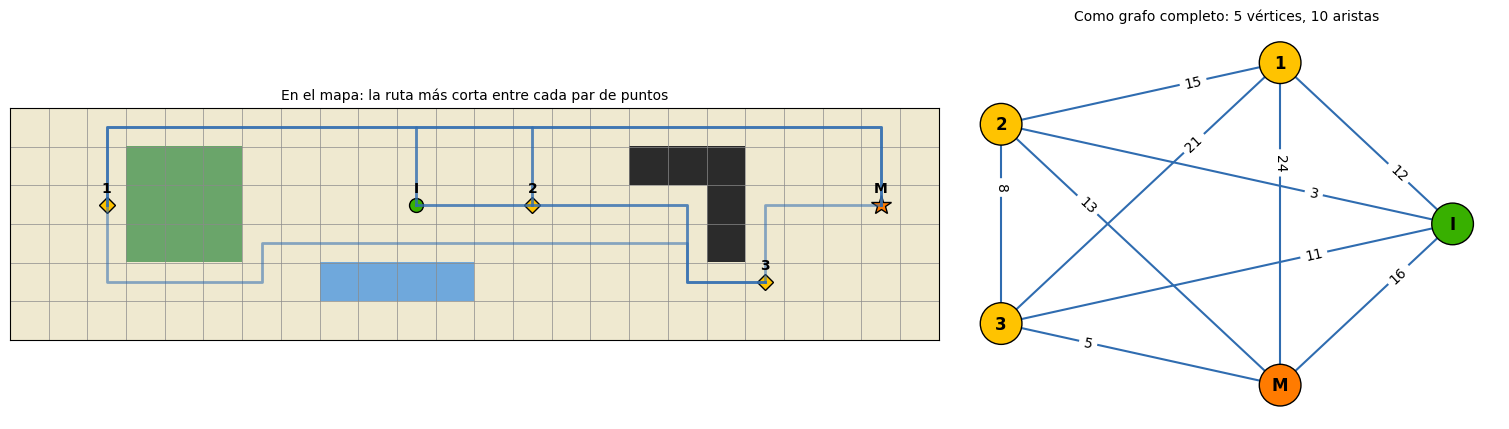

In [18]:
CON_ITEMS = '''
........................
...bbb..........###.....
..*bbb....I..*....#...M.
...bbb............#.....
........aaaa.......*....
........................
'''
dibujar_grafo_completo(CON_ITEMS)

Con 3 items el grafo completo tiene 5 vértices y $\binom{5}{2} = 10$ aristas. La tabla y el dibujo dicen lo mismo: por ejemplo, la arista entre I y 2 pesa 3 porque el item 2 está a 3 pasos del inicio, y la arista entre 1 y M pesa 24 porque hay que cruzar todo el mapa.

Con este grafo, el problema de los items se vuelve una pregunta de teoría de grafos: encontrar el camino de menor peso que sale de I, pasa exactamente una vez por cada item y termina en M. Un camino que visita todos los vértices una sola vez se llama **camino hamiltoniano**.

Dos de esos caminos se pueden seguir con el dedo sobre el dibujo:

- I, 1, 2, 3, M: 12 + 15 + 8 + 5 = **40**
- I, 2, 3, 1, M: 3 + 8 + 21 + 24 = **56**

### 4.2 Las dos estrategias

Las dos funciones siguientes trabajan sobre este grafo completo, no sobre el mapa. La fuerza bruta revisa todos los caminos hamiltonianos de I a M; el vecino más cercano construye uno solo, tomando en cada vértice la arista más barata hacia un item pendiente.

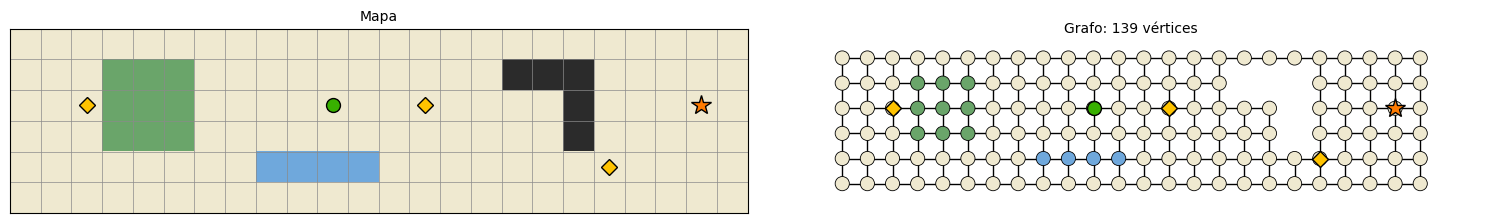

Fuerza bruta         costo   40   órdenes evaluados 6
Vecino más cercano   costo   56   órdenes evaluados 1


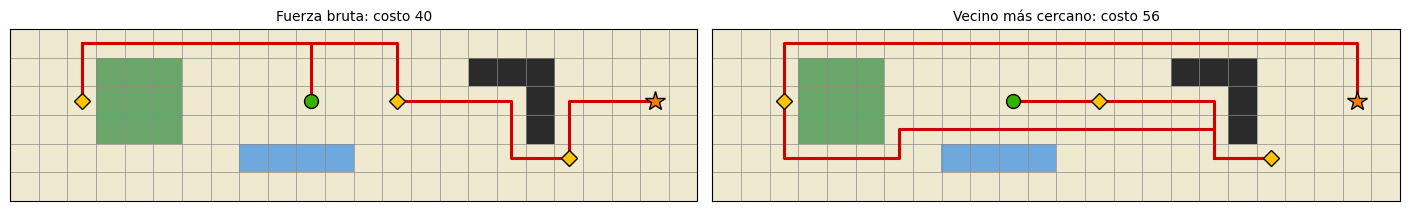

In [19]:
comparar_items(CON_ITEMS)

El vecino más cercano empieza por el item de la derecha porque está a 3 pasos, y eso lo obliga a regresar por el item de la izquierda y cruzar el mapa otra vez: costo 56. La fuerza bruta prueba los 6 órdenes y descubre que conviene ir primero al item lejano: costo 40. Una decisión buena a corto plazo resultó 40% más cara al final.

In [20]:
print(f"{'Items':<7}{'Órdenes posibles (n!)':>24}")
for n in range(1, 13):
    print(f"{n:<7}{math.factorial(n):>24,}")

Items     Órdenes posibles (n!)
1                             1
2                             2
3                             6
4                            24
5                           120
6                           720
7                         5,040
8                        40,320
9                       362,880
10                    3,628,800
11                   39,916,800
12                  479,001,600


La fuerza bruta es exacta, pero su trabajo crece como $n!$: es viable con pocos items y deja de serlo muy rápido. El vecino más cercano responde al instante con cualquier cantidad de items, a cambio de rutas que pueden ser peores.

## 5. Mapa propio

Esta celda sirve para experimentar: se puede cambiar el texto del mapa y volver a ejecutarla. Tiene que haber exactamente una `I` y una `M`. Las filas pueden medir distinto: lo que falte a la derecha de una fila corta se toma como muro, así que el mapa puede tener cualquier forma.

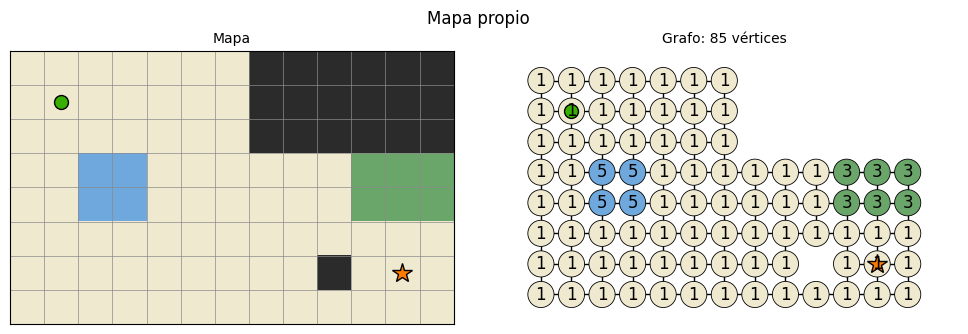

Algoritmo   Costo  Óptima  Explorados  Tiempo ms
BFS            21      no          81      0.167
DFS            21      no          22      0.049
Dijkstra       15      sí          77      0.195
Voraz          21      no          16      0.079
A*             15      sí          16      0.052


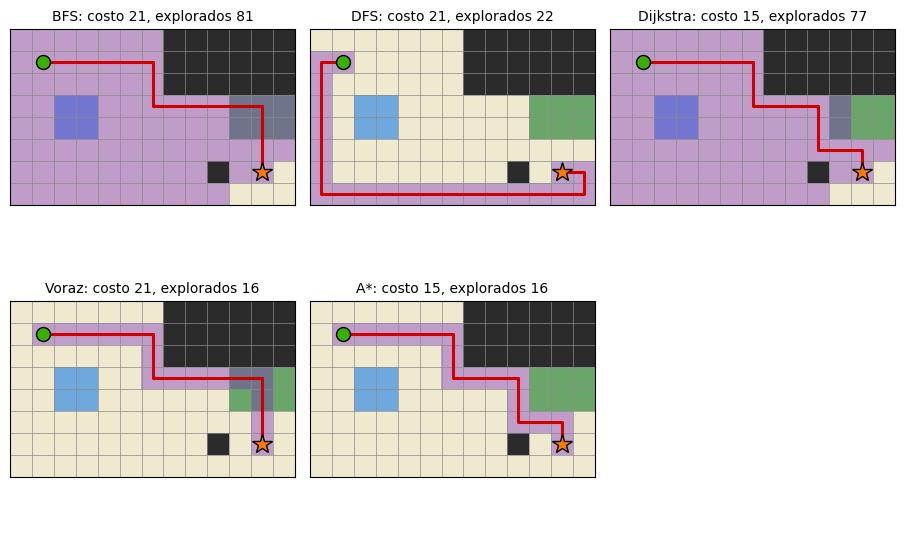

In [21]:
MI_MAPA = '''
.......
.I.....
.......
..aa......bbb
..aa......bbb
.............
.........#.M.
.............
'''
comparar(MI_MAPA, "Mapa propio")

## 6. Conclusiones

**Respuesta a la pregunta de investigación.** El algoritmo con mayor aplicabilidad para mover unidades en un mapa de videojuego es **A\***. Es el único que cumple las dos condiciones a la vez: devolvió la ruta de menor costo en todos los mapas y exploró menos que Dijkstra, el otro algoritmo que también la garantiza.

**Sobre las hipótesis**

1. *A\* iguala a Dijkstra explorando menos.* Se cumplió en todos los mapas. La diferencia depende del mapa: 18 contra 160 vértices en el mapa abierto, 83 contra 252 en el terreno mixto y solo 73 contra 83 en el laberinto.
2. *BFS solo es óptimo con costo uniforme.* Se cumplió. Fue óptimo en el mapa abierto y en el laberinto, donde todo cuesta 1, y falló en el terreno mixto (40 contra 30).
3. *DFS y la búsqueda voraz exploran poco pero no son óptimos.* Se cumplió para la búsqueda voraz, que exploró menos que todos pero devolvió rutas más caras en el terreno mixto y en el laberinto. DFS resultó peor de lo esperado: sus rutas son las más caras y además no siempre explora poco (115 vértices en el laberinto, más que cualquier otro).

**Cuándo usar cada uno**

| Algoritmo | Uso recomendado |
|---|---|
| A* | Ruta de una unidad hacia un destino. Es la opción general. |
| Dijkstra | Cuando se necesitan las distancias desde un punto hacia muchos destinos, o no hay una buena heurística. |
| BFS | Mapas donde todo el terreno cuesta lo mismo. Es el más simple de implementar. |
| Voraz | Cuando importa más responder rápido que la calidad de la ruta. |
| DFS | No sirve para calcular rutas de movimiento. |

**Límites de A\* que mostraron los experimentos**

- En laberintos su ventaja casi desaparece, porque la distancia en línea recta informa poco.
- Si no existe ruta, explora toda la componente conexa igual que los demás.
- Explorar menos vértices no siempre significa tardar menos: cada vértice le cuesta más trabajo que a BFS, y en mapas tan pequeños como estos la diferencia de tiempo puede invertirse.

**Sobre los items.** Elegir el orden de visita es un problema distinto al de encontrar la ruta entre dos puntos, y más difícil: el número de órdenes crece como $n!$. Con pocos items la fuerza bruta da el óptimo de inmediato. El vecino más cercano evalúa un solo orden, pero en el mapa de prueba su ruta costó 40% más.

**Alcance.** Estas conclusiones salen de cuatro mapas pequeños hechos a mano, y los costos óptimos se validaron contra NetworkX. Los costos y los vértices explorados son exactos y se repiten en cada ejecución; los tiempos en milisegundos cambian de una computadora a otra.